# Projectile Motion Simulator: Ideal Motion vs Air Resistance

## Research Question

How does air resistance affect a projectile's trajectory, range, and maximum height, and how accurately can a numerical simulation reproduce theoretical predictions for ideal projectile motion?

## Objectives

1. Compare an analytical model with a numerical simulation without air resistance.
2. Model the effects of quadratic air resistance.
3. Investigate numerical accuracy using different time steps.
4. Visualise and compare projectile trajectories with and without drag.

## Physical Assumptions

- The projectile launches and lands at the same height.
- Gravitational acceleration is constant.
- Air density and drag coefficient remain constant.
- The projectile is spherical, with a fixed cross-sectional area.
- Air resistance acts opposite to the velocity.
- Wind, spin, aerodynamic lift, and changes in air density are ignored.

The analytical equations apply to the ideal model without air resistance. The model with air resistance is solved numerically.

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants and projectile properties
g = 9.81                  # Gravitational acceleration (m/s^2)
rho = 1.225               # Air density (kg/m^3)
mass = 0.145              # Projectile mass (kg), baseball-like object
radius = 0.037            # Projectile radius (m)
area = np.pi * radius**2  # Cross-sectional area (m^2)
Cd = 0.47                 # Assumed drag coefficient (dimensionless)

# Numerical integration time step
dt = 0.01                 # Time step (s)

In [23]:
print("--- Simple Projectile Simulator ---")

v0 = float(input("Enter initial speed (m/s): "))
while v0 <= 0:
    print("Initial speed must be greater than 0 (m/s)")
    v0 = float(input("Enter initial speed (m/s): "))

angle_deg = float(input("Enter launch angle (degrees): "))
while angle_deg < 0 or angle_deg > 90:
    print("Angle must be between 0 and 90 degrees")
    angle_deg = float(input("Enter launch angle (degrees): "))

theta = np.radians(angle_deg)

--- Simple Projectile Simulator ---
Enter initial speed (m/s): 67
Enter launch angle (degrees): 67


In [24]:
# IDEAL MODEL: No Air Resistance
def ideal_path(v0, theta, g):
    t_flight = (2 * v0 * np.sin(theta)) / g
    t = np.linspace(0, t_flight, 500)
    x = v0 * np.cos(theta) * t
    y = v0 * np.sin(theta) * t - 0.5 * g * t**2
    return x, y

In [25]:
# Numerical Simulations
def simulate_motion(v0, theta, dt, use_drag=False):
    x, y = 0.0, 0.0
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    x_history = [x]
    y_history = [y]

    # Simulation loop runs until the projectile hits the ground
    while y >= 0.0:
        # Save old position for landing interpolation
        old_x, old_y = x, y

        # Calculate speed
        speed = np.hypot(vx, vy)

        # Calculate acceleration
        if use_drag:
            drag_factor = 0.5 * rho * Cd * area * speed / mass
            ax = -drag_factor * vx
            ay = -g - drag_factor * vy
        else:
            ax = 0.0
            ay = -g

        # Semi-implicit Euler update
        vx += ax * dt
        vy += ay * dt
        x += vx * dt
        y += vy * dt

        if y < 0:
            # Interpolate to estimate the landing point
            fraction = old_y / (old_y - y)
            impact_x = old_x + fraction * (x - old_x)

            x_history.append(impact_x)
            y_history.append(0.0)
            break

        x_history.append(x)
        y_history.append(y)

    return np.array(x_history), np.array(y_history)

In [26]:
# Run calculations
x_ideal, y_ideal = ideal_path(v0, theta, g)
x_sim, y_sim = simulate_motion(v0, theta, dt, use_drag=False)
x_drag, y_drag = simulate_motion(v0, theta, dt, use_drag=True)

# Exact analytical results for ideal projectile motion
t_flight_ideal = (2 * v0 * np.sin(theta)) / g
range_ideal = v0**2 * np.sin(2 * theta) / g
height_ideal = (v0 * np.sin(theta))**2 / (2 * g)

# Print results
print(f"\n--- Results: {v0:.2f} m/s | {angle_deg:.2f} degrees ---")
print(f"Ideal analytical model: Range = {range_ideal:.2f} m | Max height = {height_ideal:.2f} m")
print(f"Simulation, no drag: Range = {x_sim[-1]:.2f} m | Max height = {np.max(y_sim):.2f} m")
print(f"Simulation, with drag: Range = {x_drag[-1]:.2f} m | Max height = {np.max(y_drag):.2f} m")


--- Results: 67.00 m/s | 67.00 degrees ---
Ideal analytical model: Range = 329.17 m | Max height = 193.87 m
Simulation, no drag: Range = 328.90 m | Max height = 193.56 m
Simulation, with drag: Range = 91.51 m | Max height = 80.09 m


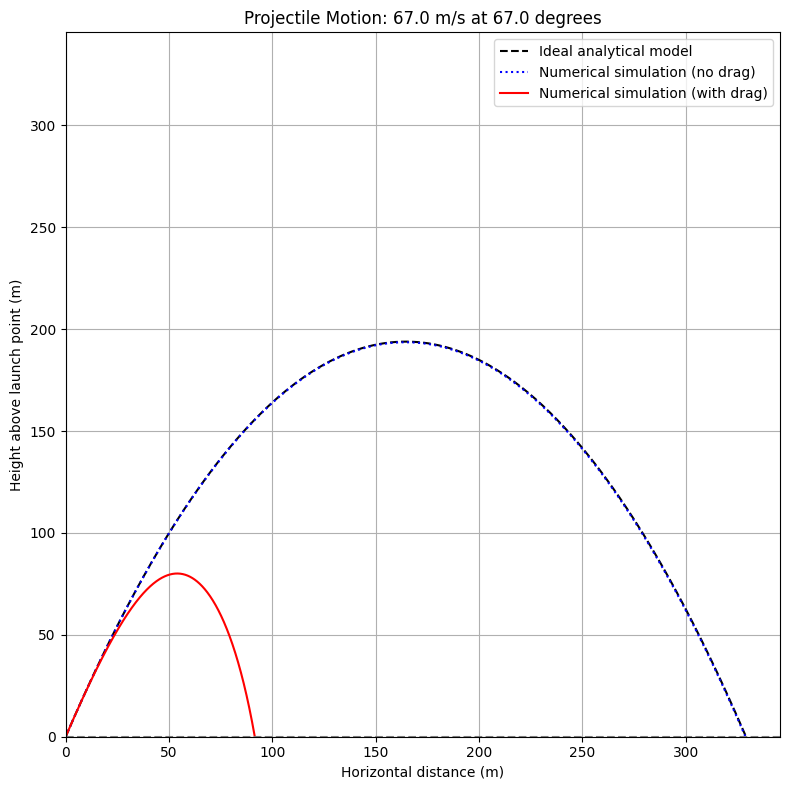

In [27]:
# Plot trajectories
plt.figure(figsize=(8, 8))
plt.plot(x_ideal, y_ideal, "k--", label="Ideal analytical model")
plt.plot(x_sim, y_sim, "b:", label="Numerical simulation (no drag)")
plt.plot(x_drag, y_drag, "r-", label="Numerical simulation (with drag)")

# Equal axis limits with a 5% margin
max_val = max(x_ideal[-1], np.max(y_ideal)) * 1.05
plt.xlim(0, max_val)
plt.ylim(0, max_val)

plt.title(f"Projectile Motion: {v0:.1f} m/s at {angle_deg:.1f} degrees")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Height above launch point (m)")
plt.axhline(0, color="gray", linestyle="--")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
# Time-step convergence test
convergence_angle = np.radians(45)
dt_values = [0.02, 0.01, 0.005, 0.001]

# Exact results at the convergence-test angle
exact_range = v0**2 * np.sin(2 * convergence_angle) / g
exact_height = (v0 * np.sin(convergence_angle))**2 / (2 * g)

range_errors = []
height_errors = []

print("\n--- Numerical Convergence Test: No Drag ---")
print(f"{'dt (s)':>10} | {'Range (m)':>12} | "f"{'Range error (%)':>16} | {'Height error (%)':>17}")
print("-" * 64)

for test_dt in dt_values:
    x_test, y_test = simulate_motion (v0, convergence_angle, test_dt, use_drag=False)

    simulated_range = x_test[-1]
    simulated_height = np.max(y_test)

    range_error = (abs(simulated_range - exact_range) / abs(exact_range)) * 100
    height_error = (abs(simulated_height - exact_height) / abs(exact_height)) * 100

    range_errors.append(range_error)
    height_errors.append(height_error)

    print(f"{test_dt:10.4f} | {simulated_range:12.5f} | "f"{range_error:16.6f} | {height_error:17.6f}")


--- Numerical Convergence Test: No Drag ---
    dt (s) |    Range (m) |  Range error (%) |  Height error (%)
----------------------------------------------------------------
    0.0200 |    456.64665 |         0.207091 |          0.413705
    0.0100 |    457.12048 |         0.103545 |          0.207041
    0.0050 |    457.35739 |         0.051772 |          0.103521
    0.0010 |    457.54691 |         0.010354 |          0.020706


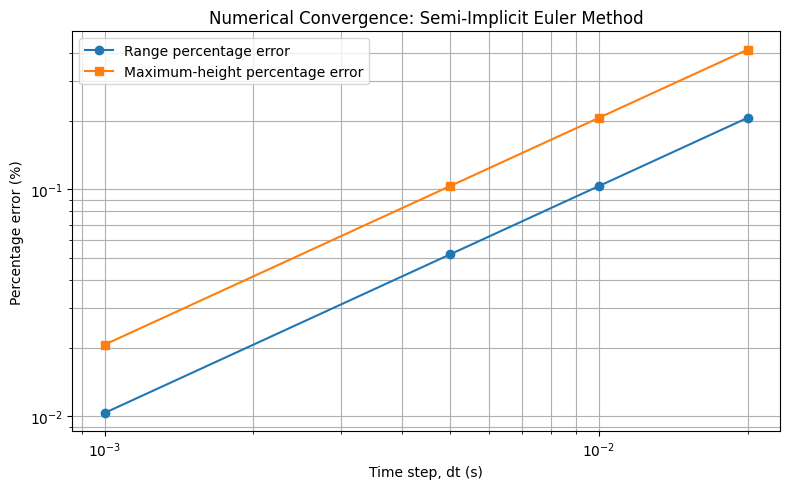

In [29]:
# Plot numerical errors against time step
plt.figure(figsize=(8, 5))
plt.loglog(dt_values, range_errors, "o-", label="Range percentage error")
plt.loglog(dt_values, height_errors, "s-",label="Maximum-height percentage error")

plt.xlabel("Time step, dt (s)")
plt.ylabel("Percentage error (%)")
plt.title("Numerical Convergence: Semi-Implicit Euler Method")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

This project compared an analytical model of ideal projectile motion with numerical simulations using the semi-implicit Euler method. A quadratic air-resistance model was also implemented to investigate how drag affects the projectile's trajectory.

The trajectory comparison illustrates the difference between ideal motion and motion subject to air resistance. The numerical convergence test examines how changing the time step affects the accuracy of the predicted range and maximum height.

### Results

- Compare the numerical range and maximum height without drag against the analytical predictions.
- Describe how air resistance changed the trajectory, range, and maximum height for the selected launch conditions.
- Explain how the numerical errors changed as the time step decreased.

### Limitations

The simulation assumes constant air density and drag coefficient, a spherical projectile, no wind or spin, and a level landing surface. The semi-implicit Euler method introduces numerical error, while landing interpolation approximates the point where the projectile reaches ground level.

The results are therefore useful for exploring projectile motion and numerical modelling, but they are not exact predictions of every real projectile trajectory.